# LULC from Sentinel-1, 3rd iteration (a): encoder comparison

This notebook is the first of three 3rd-iteration experiment notebooks (`reports/2026-11-02 Prototype runs and model experiments.md`, section 3):

| Notebook | Question |
|---|---|
| **`3rd_iteration_encoders.ipynb`** (this one) | does a different CNN encoder inside the same U-Net segment better? |
| `3rd_iteration_training.ipynb` | are the optimiser and the loss the right choice? |
| `3rd_iteration_labels.ipynb` | how much do the noisy labels limit the model, and can the training cope better with them? |

The 2nd iteration tried only one architecture: a U-Net with an ImageNet-pretrained **ResNet-34** encoder. Here the **encoder** (the downsampling half of the U-Net) is exchanged for the classic CNN architectures of lecture 07; the decoder, the skip connections and everything else stay the same.

**Fixed in every experiment** (identical to `Iter2_Test_1_Full`, the current final model): `Dataset_2nd_iteration`, the `month_year` input (current month + 9 seasonal statistics, 12 channels), the 7 classes, month dropout, augmentation, class weights and sampler, EMA, the schedule (up to 40 epochs, early stopping), the 12-month test with temporal smoothing and flicker.

**One change at a time.** Every configuration in `EXPERIMENTS` changes one setting of the reference. Each configuration is trained with **2 seeds**, because two identical runs differed by up to 0.02 mIoU (2026-10-31 report, section 11.1).

**Decision rule** (unchanged: the test set is never used for choosing):
- the best configuration is the one with the highest **mean val mIoU** over the seeds;
- it replaces the current model only if it beats the reference by more than `NOISE` = 0.02;
- the rural test mIoU (main score), flicker and per-class IoU are reported for every run.

**Reference values** of `Iter2_Test_1_Full` (1 seed): val mIoU 0.732, rural test mIoU 0.679 (smoothed 0.680), flicker 2.4 % (smoothed 0.9 %), 24.5 M parameters, 4.7 min.

Sections 2-5 are copied unchanged from `Notebooks/2nd_iteration.ipynb`; their explanations are there.

**Roadmap**

1. Settings and hardware check
2. Load the data
3. Explore the data
4. Input features
5. Datasets, augmentation and class balancing
6. The model
7. Loss and metrics
8. Training: all experiments
9. Results: comparison, curves, the best configuration
10. Export of the best run

## Glossary: new terms in this notebook

| Term | Meaning |
|---|---|
| encoder | the first half of the U-Net: convolutions and downsampling that turn the input into feature maps at 1/2 ... 1/32 resolution. Here a classification CNN from torchvision without its classifier |
| decoder | the second half: upsampling back to full resolution, joined with the encoder maps through skip connections |
| residual connection | the input of a block is added to its output (ResNet), so gradients reach early layers and deep networks train well |
| bottleneck block | 1 x 1 convolution to fewer channels, 3 x 3 convolution, 1 x 1 back to more channels (ResNet-50): deeper at similar cost |
| dense connection | each layer gets the concatenated outputs of all earlier layers in its block (DenseNet) |
| depthwise separable convolution | a 3 x 3 convolution per channel followed by a 1 x 1 convolution across channels: far fewer parameters (EfficientNet, MobileNet) |
| seed | the start value of the random number generators: decoder initialisation, patch sampling, augmentation. Different seeds give different results for the same settings |
| spread | best seed minus worst seed of one configuration: the noise a difference must exceed |

## 1. Settings and hardware check

- `EXPERIMENTS`: the configurations, each a change of `BASE` (the settings of `Iter2_Test_1_Full`). The first one must be the reference (no change). `ONLY` runs a subset, for example to repeat one encoder.
- `SEEDS`: every configuration is trained once per seed. 6 configurations x 2 seeds = 12 runs. ResNet-34 took 4.7 min per run in the 2nd iteration; ResNet-50, DenseNet-121 and VGG-16 are about 1.5-2 times slower per epoch. Expected total: 1-1.5 hours on the A6000.
- `RUN_NAME`: results folder `Weights/<RUN_NAME>/` (never overwritten). Every run's weights and history go to `runs/`, the table of all runs to `runs.csv` (written after each run, so an interruption keeps the finished runs).
- The GPU memory kept free for training is raised from 12 to 20 GB, because the larger encoders need more activation memory. The data (8 GB) still fits on the A6000.

In [1]:
RUN_NAME = "Iter3_Encoders"
NOTEBOOK = "Notebooks/3rd_iteration_encoders.ipynb"
ENCODER = "resnet34"

EXPERIMENTS = {
    "E0_resnet34":         {},                              # reference = Iter2_Test_1_Full
    "E1_vgg16_bn":         dict(encoder="vgg16_bn"),        # no residual connections
    "E2_resnet50":         dict(encoder="resnet50"),        # bottleneck blocks, deeper and wider
    "E3_densenet121":      dict(encoder="densenet121"),     # dense connections, feature reuse
    "E4_efficientnet_b0":  dict(encoder="efficientnet_b0"), # depthwise separable convolutions, small
    "E5_resnet34_scratch": dict(pretrained=False),          # what ImageNet pretraining adds for radar
}

VARIANT_NAME, VARIANT = "month_year", dict(n_months=1)   # the input of Iter2_Test_1_Full, fixed in every experiment
SEEDS = [42, 7]          # every configuration is trained once per seed (one run alone carries about +-0.02 mIoU noise)
NOISE = 0.02             # a configuration must beat the reference by more than this (mean val mIoU over the seeds)

# Every key of BASE can be changed by an experiment
BASE = dict(encoder=ENCODER, pretrained=True,
            optimizer="adamw", lr=6e-4, weight_decay=0.05,       # sgd: Nesterov momentum 0.9
            lovasz_weight=0.5,                                   # 0 = cross-entropy only
            disagree_weight=0.5,                                 # loss weight where WorldCover and Dynamic World disagree
            label_smoothing=0.1,
            bootstrap_beta=1.0)                                  # < 1: soft bootstrapping (section 7)
ONLY = None              # e.g. ["E0_resnet34"] to run a subset; None = all

MAX_EPOCHS = 40
VAL_MONTHS = list(range(12))
VAL_EVERY = 2
PATIENCE = 10
SAMPLES_PER_EPOCH = 2500
WARMUP_EPOCHS = 1
EMA_DECAY = 0.99
DROPOUT = 0.2
MONTH_DROP = 0.3
LOVASZ_SAMPLE = 0.25
CROP_JITTER = 128
SEED = SEEDS[0]          # data-side randomness before training; every run sets its own seed

CONFIGS = {name: BASE | change for name, change in EXPERIMENTS.items() if ONLY is None or name in ONLY}
REFERENCE = next(iter(EXPERIMENTS))
assert not EXPERIMENTS[REFERENCE], "the first experiment must be the reference (no changes)"
for name, cfg in CONFIGS.items():
    print(f"{name:24}", {k: v for k, v in cfg.items() if v != BASE[k]} or "reference: Iter2_Test_1_Full settings")
print(f"{len(CONFIGS)} configurations x {len(SEEDS)} seeds = {len(CONFIGS) * len(SEEDS)} runs, up to {MAX_EPOCHS} epochs each")

E0_resnet34              reference: Iter2_Test_1_Full settings
E1_vgg16_bn              {'encoder': 'vgg16_bn'}
E2_resnet50              {'encoder': 'resnet50'}
E3_densenet121           {'encoder': 'densenet121'}
E4_efficientnet_b0       {'encoder': 'efficientnet_b0'}
E5_resnet34_scratch      {'pretrained': False}
6 configurations x 2 seeds = 12 runs, up to 40 epochs each


In [2]:
import subprocess, sys
try:
    import rasterio
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])
    import rasterio

import json, math, os, shutil, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# The notebook lives in Notebooks/; data and weights live at the repository root.
ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA_DIRS = [ROOT / "Dataset_2nd_iteration", Path("../input")]
OUT = ROOT / "Weights" / RUN_NAME
if OUT.exists() and any(OUT.iterdir()):
    OUT = OUT.with_name(f"{RUN_NAME}_{time.strftime('%Y%m%d_%H%M%S')}")
    print(f"Weights/{RUN_NAME} already has files, saving to {OUT} instead")


def s1_preprocessing(root):
    first = next((root / "s1").glob("*.tif"), None)
    if first is None:
        return ""
    with rasterio.open(first) as src:
        return src.tags().get("preprocessing", "")


def find_data_root():
    """The first dataset with a patch index whose radar tiles are terrain-flattened (2nd-iteration pipeline)."""
    for base in DATA_DIRS:
        if base.exists():
            for hit in sorted(base.rglob("train_patches.csv")):
                root = hit.parent.parent
                if "gamma0" in s1_preprocessing(root):
                    return root
                print("skipping (not built by the 2nd-iteration pipeline):", root)
    raise FileNotFoundError("Dataset_2nd_iteration not found: build it with data_pipeline/ (see data_pipeline/README.md)")


DATA = find_data_root()
S1_PREPROCESSING = s1_preprocessing(DATA)
RUNS_DIR = OUT / "runs"  # weights and history of every run; the best run is copied to OUT / best_model.pt
RUNS_DIR.mkdir(parents=True, exist_ok=True)
print("data:", DATA, "| output:", OUT.resolve())
print("radar preprocessing:", S1_PREPROCESSING)

data: /home/jovyan/vault/LULC-semantic-Model/Dataset_2nd_iteration | output: /home/jovyan/vault/LULC-semantic-Model/Weights/Iter3_Encoders
radar preprocessing: S1_GRD IW VV+VH asc+desc; gamma0 terrain flattening (Vollrath 2020 volume model, GLO-30); layover/shadow/incidence 31-45 deg masked; monthly linear mean; dB; no spatial filter


### Hardware check

Unchanged from the 1st iteration (section 1 there explains every rule): bfloat16 on Ampere and newer, float16 + `GradScaler` on T4; batch 64 with ≥ 24 GB GPU memory, else 32; no DataLoader workers when `/dev/shm` is small.

In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CPU_COUNT = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
SHM_GB = shutil.disk_usage("/dev/shm").total / 1e9 if Path("/dev/shm").exists() else None

if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    GPU_NAME, GPU_MEM_GB, CAPABILITY = props.name, props.total_memory / 1e9, (props.major, props.minor)
else:
    GPU_NAME, GPU_MEM_GB, CAPABILITY = "none", 0.0, (0, 0)

USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if CAPABILITY >= (8, 0) else torch.float16
USE_SCALER = USE_AMP and AMP_DTYPE == torch.float16
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

BATCH = 64 if GPU_MEM_GB >= 24 else 32
GPU_TRAIN_RESERVE_GB = 20 if BATCH == 64 else 10   # was 12 / 7: larger encoders need more memory

# DataLoader workers hand batches over through shared memory (/dev/shm). Docker containers often
# give it only 64 MB, which kills the workers with "Bus error"; then load in the main process.
NUM_WORKERS = 0 if SHM_GB is not None and SHM_GB < 1 else min(8, CPU_COUNT)

print(f"GPU: {GPU_NAME} | {GPU_MEM_GB:.0f} GB | compute capability {CAPABILITY[0]}.{CAPABILITY[1]}")
print(f"CPU cores: {CPU_COUNT} | /dev/shm: {'n/a' if SHM_GB is None else f'{SHM_GB:.2f} GB'}")
print(f"mixed precision: {str(AMP_DTYPE).split('.')[-1] if USE_AMP else 'off'}{' + GradScaler' if USE_SCALER else ''}"
      f" | batch {BATCH} | DataLoader workers {NUM_WORKERS} (only used if the data does not fit on the GPU)")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| rasterio", rasterio.__version__)

GPU: NVIDIA RTX A6000 | 51 GB | compute capability 8.6
CPU cores: 32 | /dev/shm: 0.07 GB
mixed precision: bfloat16 | batch 64 | DataLoader workers 0 (only used if the data does not fit on the GPU)
torch 2.9.1+cu128 | torchvision 0.24.1+cu128 | rasterio 1.4.4


### Dataset constants

- **Radar values** are uint8 codes: `dB = code * 0.2 - 35`, code 0 = no data (also layover and shadow).
- **Classes** (7; 1st iteration: 8):

| Class | Includes | WorldCover |
|---|---|---|
| Man-made | buildings, roads, paved yards, railways | 50 |
| Crop fields | land ploughed and harvested each year | 40 |
| Trees | forest, orchards, plantations, mangrove | 10, 95 |
| Grassland | pasture, meadows, steppe, shrub and scrub, marsh | 20, 30, 90 |
| Bare ground | desert, rock, sand, sparse vegetation | 60, 100 |
| Water | lakes, rivers, sea | 80 |
| Snow & ice | glaciers, permanent snow | 70 |

- **Label code** (one int16 array per tile, so labels and agreement travel together through cropping, flips and the GPU):
  - `0 ... 6`: class index, WorldCover and Dynamic World agree;
  - `7 ... 13`: class index + 7, only WorldCover (the maps disagree);
  - `-1`: no WorldCover data (ignored).

  `split_label` turns a code into the class index and the agreement mask.

In [4]:
CLASS_NAMES = ["Man-made", "Crop fields", "Trees", "Grassland", "Bare ground", "Water", "Snow & ice"]
CLASS_COLORS = ["#e31a1c", "#ffd92f", "#1a9850", "#a6d96a", "#bf812d", "#2c7fb8", "#dfe9f0"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
N_CLASSES = len(CLASS_NAMES)
IGNORE = -1
PATCH = 256
DB_MIN, DB_STEP = -35.0, 0.2

DB_LUT = (np.arange(256, dtype=np.float32) * DB_STEP + DB_MIN)
DB_LUT[0] = np.nan

CMAP = ListedColormap(["#000000"] + CLASS_COLORS)
LEGEND = [Patch(color=c, label=n) for n, c in zip(["no label"] + CLASS_NAMES, ["#000000"] + CLASS_COLORS)]


def label_classes(y):
    """numpy label codes -> class index (IGNORE where no label)."""
    return np.where(y >= 0, y % N_CLASSES, IGNORE)


def split_label(y):
    """torch label codes -> (class index or IGNORE, mask of pixels where both label maps agree)."""
    target = torch.where(y >= 0, y % N_CLASSES, torch.full_like(y, IGNORE))
    return target, (y >= 0) & (y < N_CLASSES)

## 2. Load the data

Same layout as the 1st iteration: 1024 × 1024 px tiles (10.24 km), 12 months × 2 polarisations; `patches/<split>_patches.csv` lists the 256 × 256 windows. Train keeps the full tiles in memory (random crops around the indexed windows); val and test use the fixed windows. Splits are **by site**.

New: the label is WorldCover (band 2 of the label file) on every pixel, with the consensus band (band 1) marking agreement.

In [5]:
SPLITS = ["train", "val", "test"]
index = {s: pd.read_csv(DATA / "patches" / f"{s}_patches.csv") for s in SPLITS}
for s in SPLITS:
    rural = index[s][index[s].focus != "urban"].site.nunique()
    print(f"{s:5}: {len(index[s]):5} patches from {index[s].site.nunique():3} sites ({rural} rural)")


def read_site(site):
    with rasterio.open(DATA / "s1" / f"{site}.tif") as src:
        s1 = src.read().reshape(12, 2, src.height, src.width)
    with rasterio.open(DATA / "labels" / f"{site}.tif") as src:
        consensus, worldcover = src.read(1), src.read(2)
    label = worldcover.astype(np.int16) - 1
    label[(worldcover > 0) & (consensus == 0)] += N_CLASSES
    return s1, label


TILE_X, TILE_Y = {}, {}
X, Y = {}, {}
t0 = time.time()
for s in SPLITS:
    df = index[s]
    if s != "train":
        X[s] = np.empty((len(df), 12, 2, PATCH, PATCH), dtype=np.uint8)
        Y[s] = np.empty((len(df), PATCH, PATCH), dtype=np.int16)
    for site, rows in df.groupby("site"):
        s1, label = read_site(site)
        if s == "train":
            TILE_X[site], TILE_Y[site] = s1, label
            continue
        for i, r, c in zip(rows.index, rows.row, rows.col):
            X[s][i] = s1[:, :, r:r + PATCH, c:c + PATCH]
            Y[s][i] = label[r:r + PATCH, c:c + PATCH]

TRAIN_ORIGINS = list(zip(index["train"].site, index["train"].row, index["train"].col))


def train_window(i, dr=0, dc=0):
    site, r, c = TRAIN_ORIGINS[i]
    size = TILE_Y[site].shape[0]
    return site, int(np.clip(r + dr, 0, size - PATCH)), int(np.clip(c + dc, 0, size - PATCH))


def train_patch(i, dr=0, dc=0):
    site, r, c = train_window(i, dr, dc)
    return TILE_X[site][:, :, r:r + PATCH, c:c + PATCH], TILE_Y[site][r:r + PATCH, c:c + PATCH]


Y["train"] = np.stack([train_patch(i)[1] for i in range(len(TRAIN_ORIGINS))])
gb = (sum(t.nbytes for t in TILE_X.values()) + sum(x.nbytes for x in X.values())) / 1e9
print(f"loaded in {time.time() - t0:.0f}s, {gb:.2f} GB of radar data in memory")

train:  2218 patches from 139 sites (114 rural)
val  :   335 patches from  21 sites (18 rural)
test :   265 patches from  17 sites (13 rural)
loaded in 27s, 4.44 GB of radar data in memory


## 3. Explore the data

**Class distribution and agreement.** The share of each class among WorldCover-labelled pixels, and how often Dynamic World agrees. Low agreement marks classes whose labels are uncertain (typically grassland and the edges between classes), which is why disagreement pixels get a lower loss weight.

,train %,val %,test %,train agreement %
Man-made,9.1,7.8,15.2,95.0
Crop fields,16.0,13.3,16.5,71.9
Trees,33.9,28.6,28.1,78.0
Grassland,25.5,31.4,28.4,55.1
Bare ground,7.4,10.2,7.5,70.7
Water,5.4,4.9,2.1,96.0
Snow & ice,2.8,3.8,2.3,93.2


train: 73.6% of labelled pixels are agreement pixels
val: 72.7% of labelled pixels are agreement pixels
test: 75.6% of labelled pixels are agreement pixels


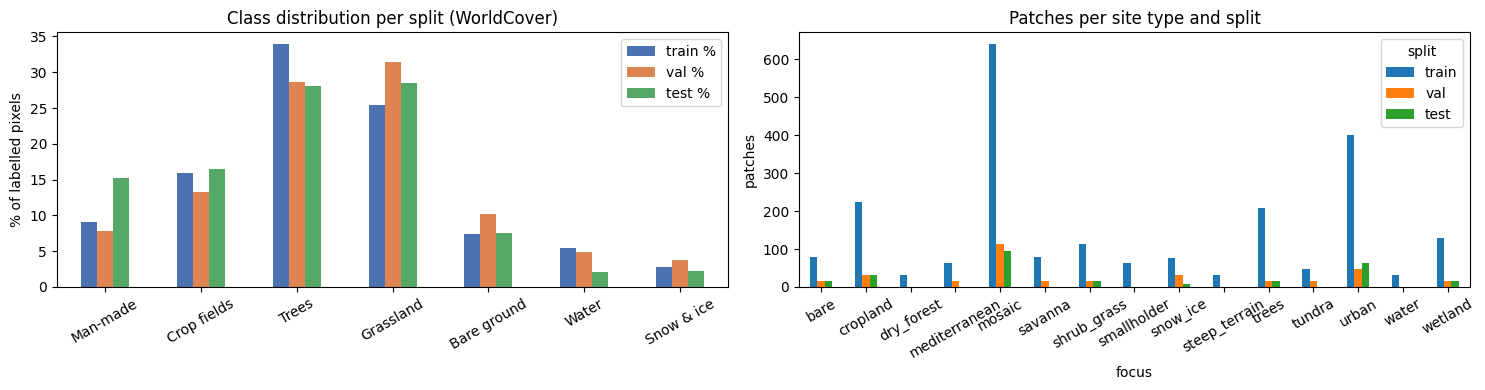

In [6]:
counts = {s: np.bincount(label_classes(Y[s])[Y[s] >= 0].ravel(), minlength=N_CLASSES) for s in SPLITS}
agree_counts = {s: np.bincount(Y[s][(Y[s] >= 0) & (Y[s] < N_CLASSES)].ravel(), minlength=N_CLASSES) for s in SPLITS}
dist = pd.DataFrame({f"{s} %": counts[s] / counts[s].sum() * 100 for s in SPLITS}, index=CLASS_NAMES)
dist["train agreement %"] = agree_counts["train"] / np.maximum(counts["train"], 1) * 100
display(dist.round(1))
for s in SPLITS:
    print(f"{s}: {agree_counts[s].sum() / counts[s].sum() * 100:.1f}% of labelled pixels are agreement pixels")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
dist[[f"{s} %" for s in SPLITS]].plot.bar(ax=axes[0], color=["#4c72b0", "#dd8452", "#55a868"])
axes[0].set_ylabel("% of labelled pixels")
axes[0].set_title("Class distribution per split (WorldCover)")
axes[0].tick_params(axis="x", rotation=30)
all_patches = pd.concat([index[s].assign(split=s) for s in SPLITS], ignore_index=True)
pd.crosstab(all_patches.focus, all_patches.split)[SPLITS].plot.bar(ax=axes[1])
axes[1].set_ylabel("patches")
axes[1].set_title("Patches per site type and split")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**What the radar sees** (R = VV, G = VH, B = VV - VH; explained in the 1st iteration, section 3). With terrain flattening, hillsides in mosaic tiles should no longer show a bright / dark stripe pattern that follows the relief. Black in the agreement row marks pixels where the two label maps disagree: they cluster along boundaries.

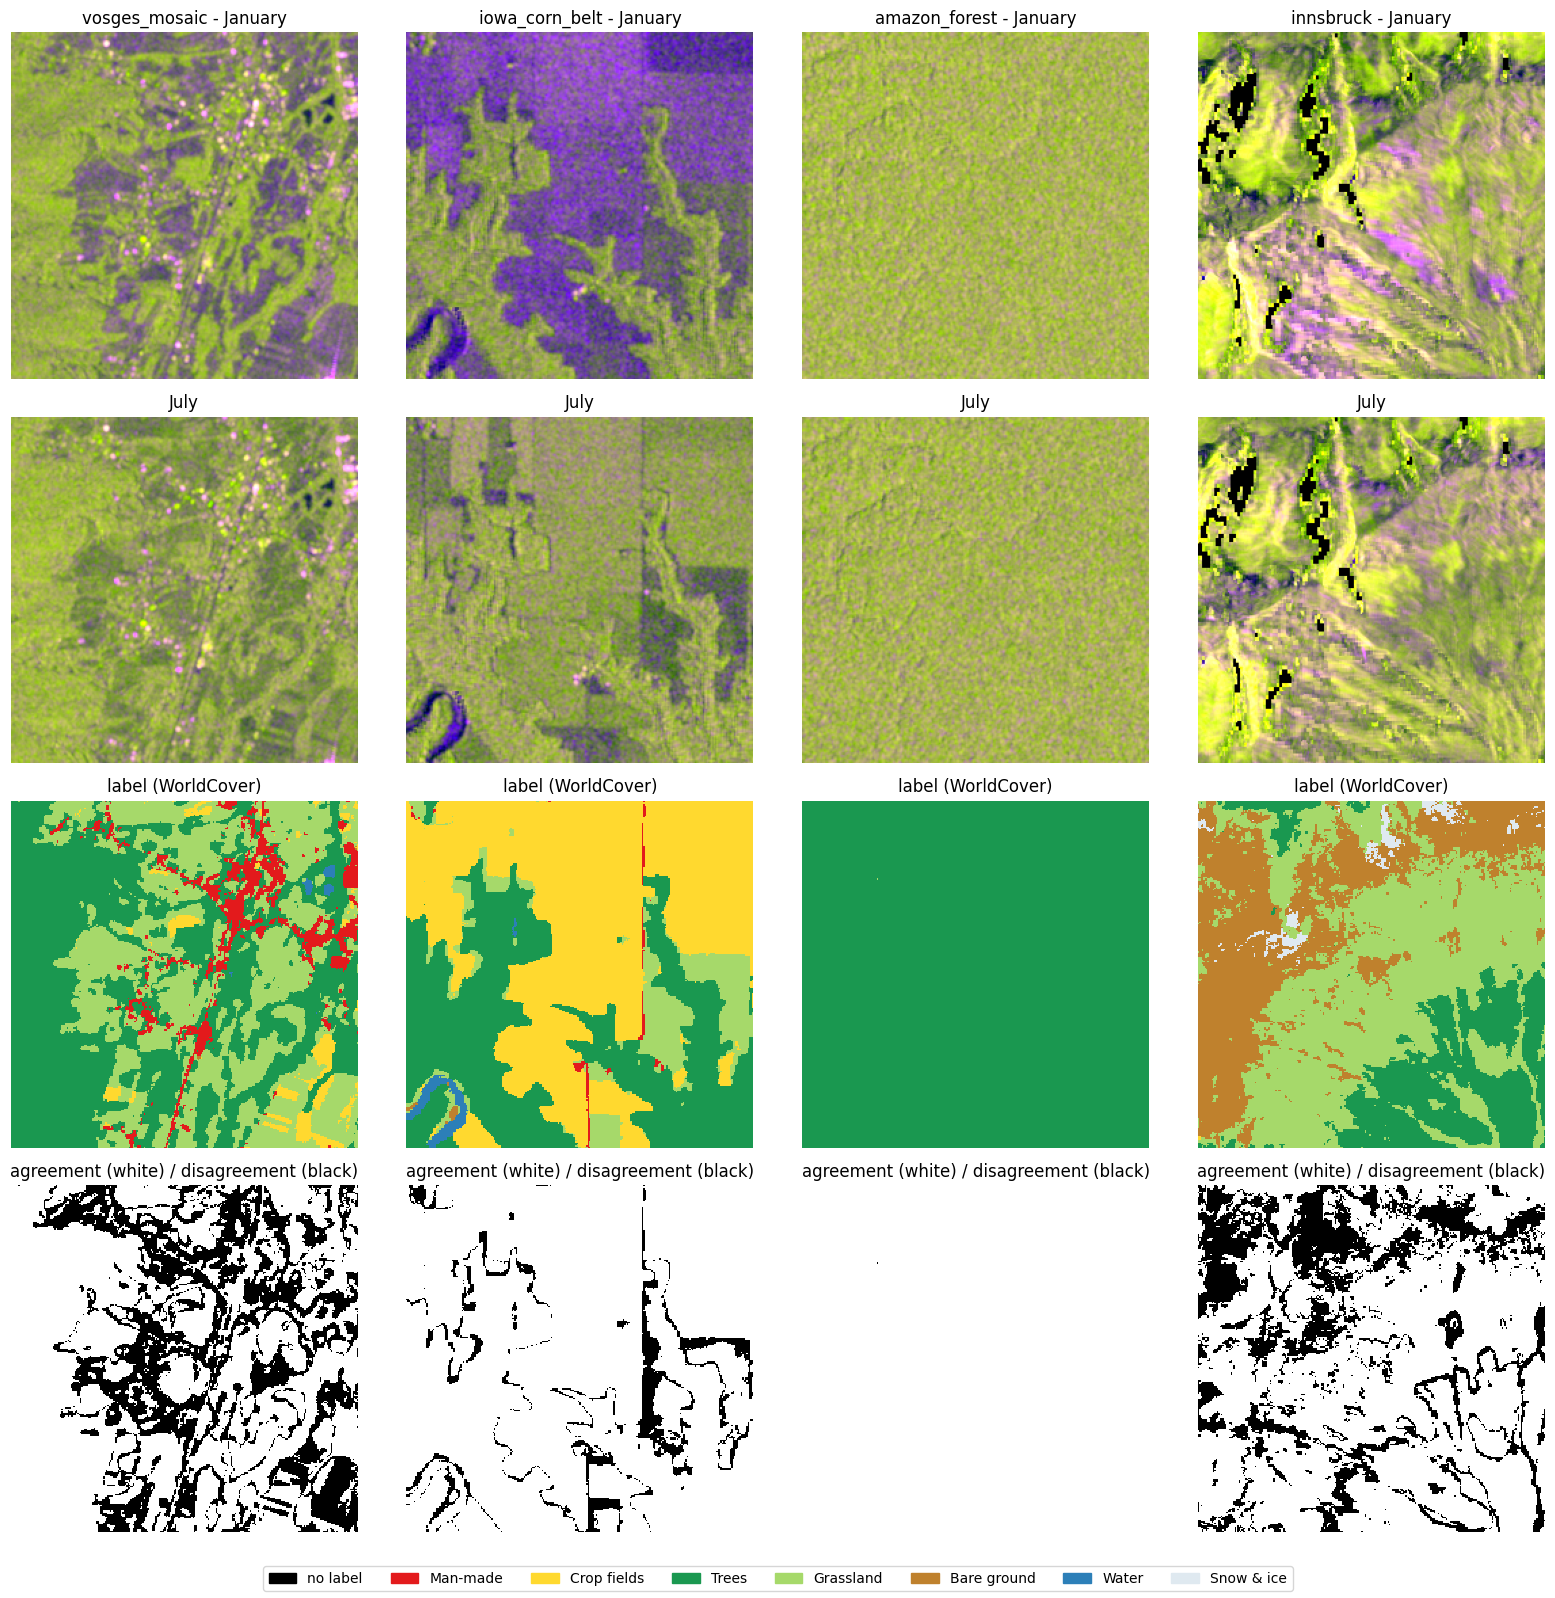

In [7]:
def false_colour(codes_2hw):
    vv, vh = DB_LUT[codes_2hw[0]], DB_LUT[codes_2hw[1]]
    rgb = np.stack([vv, vh, vv - vh], -1)
    for b, (lo, hi) in enumerate([(-20, 0), (-27, -7), (2, 15)]):
        rgb[..., b] = np.clip((rgb[..., b] - lo) / (hi - lo), 0, 1)
    return np.nan_to_num(rgb)


focus_types = [f for f in ["mosaic", "cropland", "trees", "urban"] if f in set(index["train"].focus)]
examples = [index["train"][index["train"].focus == f].index[0] for f in focus_types]
fig, axes = plt.subplots(4, len(examples), figsize=(4 * len(examples), 16), squeeze=False)
for j, i in enumerate(examples):
    x, y = train_patch(i)
    axes[0, j].imshow(false_colour(x[0]))
    axes[0, j].set_title(f"{index['train'].site[i]} - January")
    axes[1, j].imshow(false_colour(x[6]))
    axes[1, j].set_title("July")
    axes[2, j].imshow(label_classes(y) + 1, cmap=CMAP, vmin=0, vmax=N_CLASSES, interpolation="nearest")
    axes[2, j].set_title("label (WorldCover)")
    axes[3, j].imshow((y >= 0) & (y < N_CLASSES), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[3, j].set_title("agreement (white) / disagreement (black)")
for ax in axes.ravel():
    ax.axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=9)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 4. Input features: monthly channels and seasonal statistics

**Monthly channels** (unchanged): VV, VH and VV - VH in dB per input month, standardised with train-only statistics; missing pixels become 0 (the channel mean). The month window wraps around the year (January uses November and December).

**Seasonal statistics** (every variant). Rural land-cover classes are defined by their yearly cycle: fields are ploughed, grow and are harvested; grassland stays green; forest is stable; water is dark all year. The statistics describe that cycle **without depending on the month order**, so they work the same in both hemispheres (the reason PCA was dropped, see the 1st iteration, section 5, and `reports/literature survey_reiterate.md`):

| Channel | Meaning | Helps with |
|---|---|---|
| VV mean, VH mean, VV-VH mean | the average signal over the year | city vs forest vs field vs water |
| VV low, VH low | 2nd darkest month (robust minimum) | water (always dark), snow and frozen ground (dark in winter only) |
| VV high, VH high | 2nd brightest month (robust maximum) | crops at full growth, buildings |
| VH std | how much the vegetation signal varies over the year | cropland (strong cycle) vs trees and grassland (weak) |
| water months | share of months with VV below -18 dB | permanent water (~1) vs seasonally flooded wetland (between 0 and 1) |

A winter month that looks like water can no longer flip a forest pixel on its own: the yearly statistics still say "forest". Month dropout (section 5) teaches the model to trust them.

All statistics are standardised with train statistics and computed **once** per tile (float16).

channel mean (VV, VH, VV-VH): [ -9.719 -16.933   7.214]
channel std  (VV, VH, VV-VH): [4.522 4.864 2.549]
9 seasonal statistics precomputed in 79s (3.3 GB)


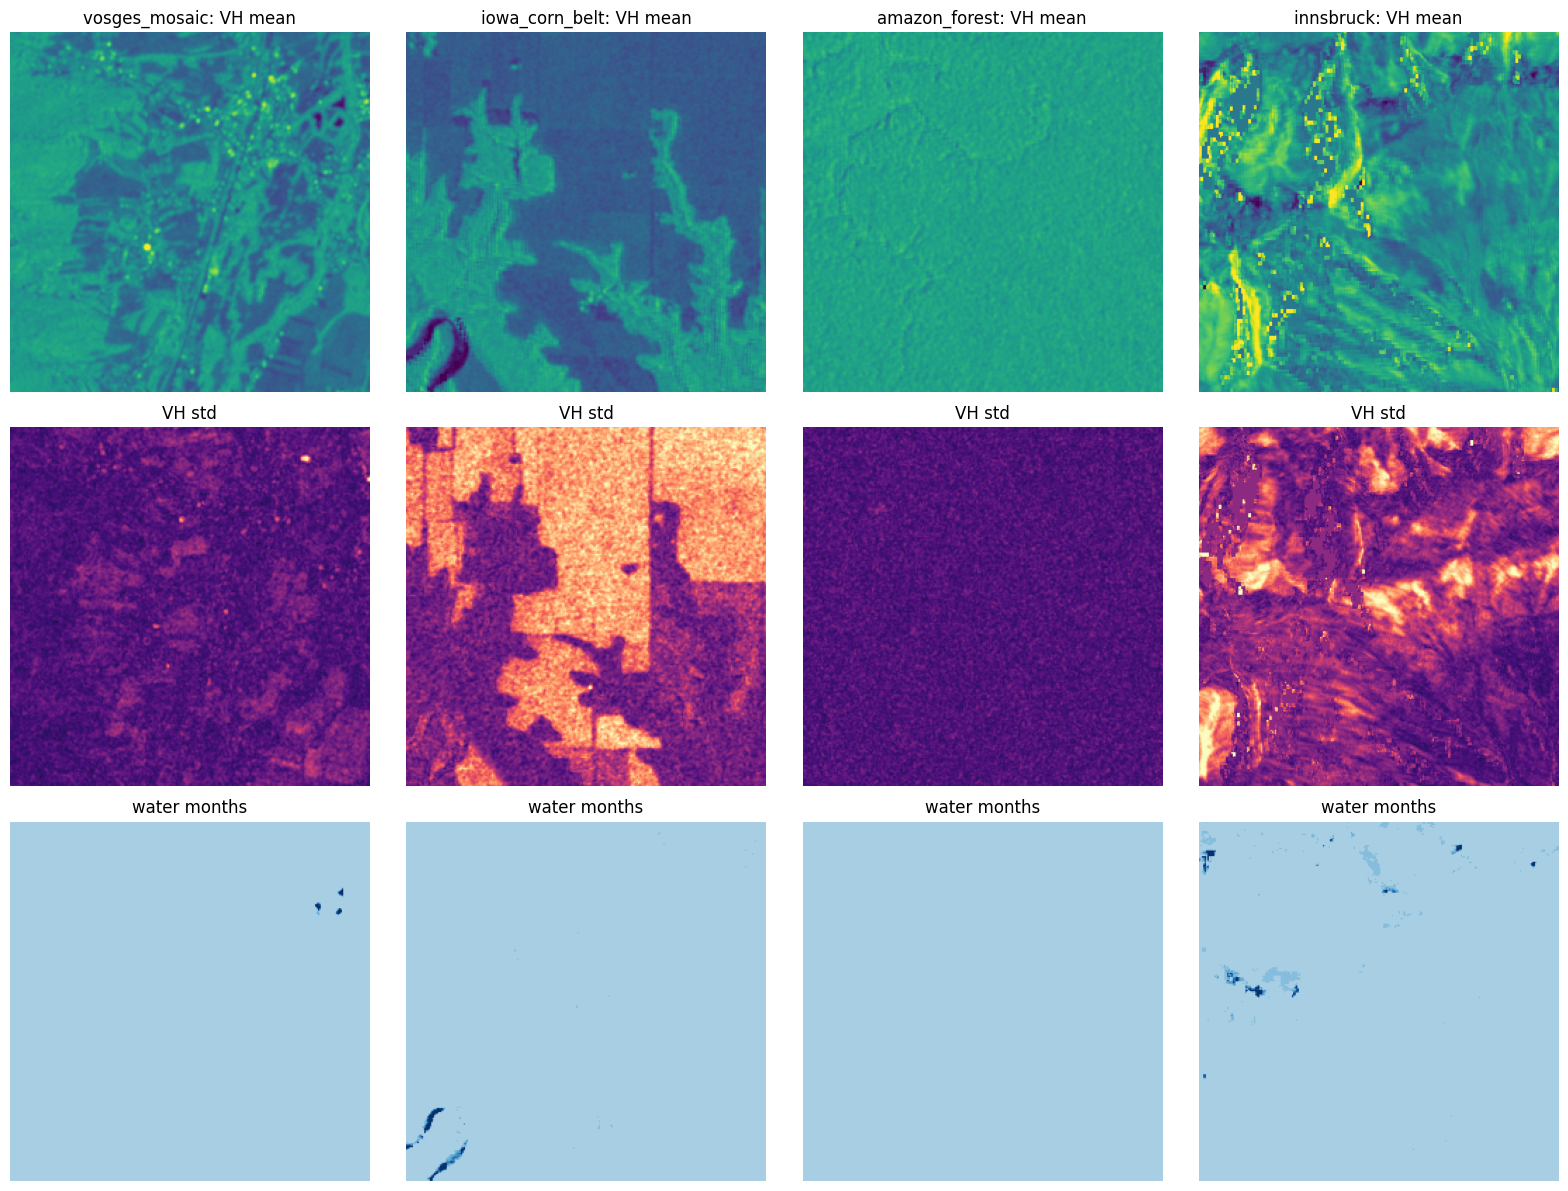

In [8]:
def standardise(f, mean, std):
    return np.nan_to_num((f - mean[None, :, None, None]) / std[None, :, None, None], nan=0.0)


def window_months(month, n_months):
    return [(month - j) % 12 for j in range(n_months - 1, -1, -1)]


def take_months(codes, months):
    """codes (12, 2, H, W) -> (len(months), 2, H, W); an empty month list gives an empty array (year_stats)."""
    return codes[months] if months else codes[:0]


sample = DB_LUT[np.stack([train_patch(i)[0][:, :, ::4, ::4] for i in range(0, len(TRAIN_ORIGINS), 4)])]
feats = np.stack([sample[:, :, 0], sample[:, :, 1], sample[:, :, 0] - sample[:, :, 1]], 0).reshape(3, -1)
CH_MEAN = np.nanmean(feats, axis=1).astype(np.float32)
CH_STD = np.nanstd(feats, axis=1).astype(np.float32)
del sample, feats
print("channel mean (VV, VH, VV-VH):", CH_MEAN.round(3))
print("channel std  (VV, VH, VV-VH):", CH_STD.round(3))

WATER_DB = -18.0
STAT_NAMES = ["VV mean", "VH mean", "VV-VH mean", "VV low", "VV high", "VH low", "VH high", "VH std", "water months"]
N_STATS = len(STAT_NAMES)


def stats_raw(codes):
    db = DB_LUT[codes]
    vv, vh = db[:, 0], db[:, 1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        vv_sorted = np.sort(np.where(np.isnan(vv), np.nanmean(vv, 0), vv), 0)
        vh_sorted = np.sort(np.where(np.isnan(vh), np.nanmean(vh, 0), vh), 0)
        n_valid = np.maximum((~np.isnan(vv)).sum(0), 1)
        out = np.stack([np.nanmean(vv, 0), np.nanmean(vh, 0), np.nanmean(vv - vh, 0),
                        vv_sorted[1], vv_sorted[-2], vh_sorted[1], vh_sorted[-2],
                        np.nanstd(vh, 0), (vv < WATER_DB).sum(0) / n_valid])
    return out.astype(np.float32)


def fit_mean_std(maps):
    flat = np.concatenate([m.reshape(m.shape[0], -1) for m in maps], 1)
    return np.nanmean(flat, 1).astype(np.float32), np.nanstd(flat, 1).astype(np.float32)


STAT_MEAN, STAT_STD = fit_mean_std([stats_raw(train_patch(i)[0][:, :, ::8, ::8])
                                    for i in range(0, len(TRAIN_ORIGINS), 2)])
STAT_STD = np.maximum(STAT_STD, 1e-3)


def stats_maps(codes, rows=128):
    out = np.empty((N_STATS, *codes.shape[-2:]), dtype=np.float16)
    for r in range(0, codes.shape[-2], rows):
        out[:, r:r + rows] = standardise(stats_raw(codes[:, :, r:r + rows])[None], STAT_MEAN, STAT_STD)[0]
    return out


t0 = time.time()
STATIC_TILE = {site: stats_maps(x) for site, x in TILE_X.items()}
STATIC_X = {s: np.stack([stats_maps(x) for x in X[s]]) for s in ("val", "test")}
gb = (sum(m.nbytes for m in STATIC_TILE.values()) + sum(m.nbytes for m in STATIC_X.values())) / 1e9
print(f"{N_STATS} seasonal statistics precomputed in {time.time() - t0:.0f}s ({gb:.1f} GB)")

fig, axes = plt.subplots(3, len(examples), figsize=(4 * len(examples), 12), squeeze=False)
for j, i in enumerate(examples):
    site, r, c = train_window(i)
    s = STATIC_TILE[site][:, r:r + PATCH, c:c + PATCH].astype(np.float32)
    for row, (name, cmap) in enumerate([("VH mean", "viridis"), ("VH std", "magma"), ("water months", "Blues")]):
        axes[row, j].imshow(s[STAT_NAMES.index(name)], cmap=cmap, vmin=-2, vmax=3)
        axes[row, j].set_title(f"{site}: {name}" if row == 0 else name)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**How to read this.** *VH mean* is bright for forest and buildings, dark for water and bare soil. *VH std* is bright where vegetation changes over the year (fields) and dark for forest, cities and water. *Water months* is dark blue for permanent water and lighter for land that is flooded only in some months.

## 5. Datasets, augmentation and class balancing

Unchanged from the 1st iteration (section 6 there): one item = one patch, one random target month, the annual label; random crop position (±128 px), flips and 90° rotations, VV / VH brightness shift (±1 dB) and 0.5 dB noise; class weights `sqrt(median_freq / freq)` and a class-aware patch sampler; batches cut on the GPU when the data fits.

Changed:
- **Month dropout 0.3.** Each input month is blanked with chance `MONTH_DROP` (for `month_year` that is the whole monthly input). The model then has only the yearly statistics and must still get the class right, which is exactly what stops a dark winter month from turning forest into water.
- **No PCA or terrain channels**: the static input is the 9 seasonal statistics for every variant.
- `year_stats` has no monthly input at all (`take_months` with an empty window).
- Class weights and the patch sampler count every WorldCover pixel.

In [9]:
def window_codes(codes, month, variant):
    return take_months(codes, window_months(month, variant["n_months"]))


LUT_T = torch.tensor(DB_LUT, device=DEVICE)
CH_MEAN_T = torch.tensor(CH_MEAN, device=DEVICE).view(1, 1, 3, 1, 1)
CH_STD_T = torch.tensor(CH_STD, device=DEVICE).view(1, 1, 3, 1, 1)


def gpu_input(codes, static, shift_db=None, month_drop=0.0):
    """uint8 codes (B, months, 2, H, W) + float16 statistics (B, S, H, W) -> standardised model input on the GPU.

    VV, VH, VV-VH per month (oldest first), then the seasonal statistics. shift_db (B, 2) adds the VV / VH
    brightness shift and 0.5 dB noise; month_drop blanks each month with this chance (code 0 -> 0 after
    standardisation).
    """
    static = static.to(DEVICE, non_blocking=True).float()
    if codes.shape[1] == 0:
        return static.contiguous(memory_format=torch.channels_last)
    codes = codes.to(DEVICE, non_blocking=True).long()
    if month_drop > 0:
        drop = torch.rand(codes.shape[:2], device=DEVICE) < month_drop
        codes = codes.masked_fill(drop[:, :, None, None, None], 0)
    db = LUT_T[codes]
    if shift_db is not None:
        db = db + shift_db.view(-1, 1, 2, 1, 1) + 0.5 * torch.randn_like(db)
    vv, vh = db[:, :, 0], db[:, :, 1]
    f = torch.nan_to_num((torch.stack([vv, vh, vv - vh], 2) - CH_MEAN_T) / CH_STD_T, nan=0.0).flatten(1, 2)
    return torch.cat([f, static], 1).contiguous(memory_format=torch.channels_last)


def gpu_augment(x, y):
    """Random flips and 90-degree rotations, drawn per sample."""
    for i in range(len(x)):
        dims = [d for d, flip in zip((-1, -2), torch.rand(2) < 0.5) if flip]
        xi, yi = (x[i].flip(dims), y[i].flip(dims)) if dims else (x[i], y[i])
        k = int(torch.randint(4, ()))
        x[i], y[i] = torch.rot90(xi, k, (-2, -1)), torch.rot90(yi, k, (-2, -1))
    return x, y


def input_channels(variant):
    return 3 * variant["n_months"] + N_STATS


class TrainDataset(Dataset):
    def __init__(self, variant):
        self.variant = variant

    def __len__(self):
        return len(TRAIN_ORIGINS)

    def __getitem__(self, i):
        site, r, c = train_window(i, *np.random.randint(-CROP_JITTER, CROP_JITTER + 1, 2))
        month = np.random.randint(12)
        codes = window_codes(TILE_X[site][:, :, r:r + PATCH, c:c + PATCH], month, self.variant)
        static = STATIC_TILE[site][:, r:r + PATCH, c:c + PATCH]
        label = TILE_Y[site][r:r + PATCH, c:c + PATCH].astype(np.int64)
        return torch.from_numpy(codes), torch.from_numpy(static), torch.from_numpy(label), month


class EvalDataset(Dataset):
    def __init__(self, x, y, static, variant, months=range(12)):
        self.x, self.y, self.static, self.variant = x, y, static, variant
        self.items = [(i, m) for i in range(len(x)) for m in months]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, k):
        i, month = self.items[k]
        codes = window_codes(self.x[i], month, self.variant)
        return (torch.from_numpy(codes), torch.from_numpy(self.static[i]),
                torch.from_numpy(self.y[i].astype(np.int64)), month)


def seed_worker(worker_id):
    np.random.seed(torch.initial_seed() % 2 ** 32)


def size_gb(arrays):
    return sum(a.nbytes for a in arrays) / 1e9


EVAL_SPLITS = ("val", "test")
train_gb = size_gb([*TILE_X.values(), *STATIC_TILE.values(), *TILE_Y.values()])
eval_gb = size_gb([X[s] for s in EVAL_SPLITS] + [STATIC_X[s] for s in EVAL_SPLITS] + [Y[s] for s in EVAL_SPLITS])
free_gb = 0.9 * GPU_MEM_GB - GPU_TRAIN_RESERVE_GB
EVAL_ON_GPU = DEVICE.type == "cuda" and eval_gb <= free_gb
TRAIN_ON_GPU = EVAL_ON_GPU and eval_gb + train_gb <= free_gb

if EVAL_ON_GPU:
    X_GPU = {s: torch.from_numpy(X[s]).to(DEVICE) for s in EVAL_SPLITS}
    STATIC_GPU = {s: torch.from_numpy(STATIC_X[s]).to(DEVICE) for s in EVAL_SPLITS}
    Y_GPU = {s: torch.from_numpy(Y[s]).to(DEVICE) for s in EVAL_SPLITS}

TRAIN_SITE_ID = {site: k for k, site in enumerate(TILE_X)}
if TRAIN_ON_GPU:
    size = max(TILE_Y[site].shape[0] for site in TILE_X)
    TILE_X_GPU = torch.zeros((len(TILE_X), 12, 2, size, size), dtype=torch.uint8, device=DEVICE)
    TILE_S_GPU = torch.zeros((len(TILE_X), N_STATS, size, size), dtype=torch.float16, device=DEVICE)
    TILE_Y_GPU = torch.full((len(TILE_X), size, size), IGNORE, dtype=torch.int16, device=DEVICE)
    for site, k in TRAIN_SITE_ID.items():
        h, w = TILE_Y[site].shape
        TILE_X_GPU[k, :, :, :h, :w] = torch.from_numpy(TILE_X[site])
        TILE_S_GPU[k, :, :h, :w] = torch.from_numpy(STATIC_TILE[site])
        TILE_Y_GPU[k, :h, :w] = torch.from_numpy(TILE_Y[site])

print(f"data: train {train_gb:.1f} GB, val + test {eval_gb:.1f} GB | GPU space for data: {max(free_gb, 0):.1f} GB")
print("train batches:", "cut on the GPU" if TRAIN_ON_GPU else f"DataLoader, {NUM_WORKERS} workers",
      "| val/test batches:", "cut on the GPU" if EVAL_ON_GPU else f"DataLoader, {NUM_WORKERS} workers")


def gpu_train_batches(variant, steps):
    """Same sampling as TrainDataset + WeightedRandomSampler, but cut from the tiles on the GPU."""
    ids = torch.multinomial(torch.as_tensor(PATCH_WEIGHTS, dtype=torch.double), steps * BATCH, replacement=True)
    for b in range(steps):
        codes, static, labels = [], [], []
        for i in ids[b * BATCH:(b + 1) * BATCH].tolist():
            site, r, c = train_window(i, *np.random.randint(-CROP_JITTER, CROP_JITTER + 1, 2))
            k = TRAIN_SITE_ID[site]
            months = window_months(np.random.randint(12), variant["n_months"])
            codes.append(take_months(TILE_X_GPU[k, :, :, r:r + PATCH, c:c + PATCH], months))
            static.append(TILE_S_GPU[k, :, r:r + PATCH, c:c + PATCH])
            labels.append(TILE_Y_GPU[k, r:r + PATCH, c:c + PATCH])
        yield torch.stack(codes), torch.stack(static), torch.stack(labels).long()


def eval_batches(split, variant, months=range(12), ids=None):
    """Fixed val/test patches, each with every month in `months`: (codes, static, label, month) batches."""
    ids = range(len(X[split])) if ids is None else [int(i) for i in ids]
    if not EVAL_ON_GPU:
        sel = slice(None) if isinstance(ids, range) else ids
        ds = EvalDataset(X[split][sel], Y[split][sel], STATIC_X[split][sel], variant, months)
        yield from DataLoader(ds, 2 * BATCH, num_workers=NUM_WORKERS, pin_memory=True)
        return
    items = [(i, m) for i in ids for m in months]
    for b in range(0, len(items), 2 * BATCH):
        chunk = items[b:b + 2 * BATCH]
        codes = torch.stack([take_months(X_GPU[split][i], window_months(m, variant["n_months"])) for i, m in chunk])
        static = torch.stack([STATIC_GPU[split][i] for i, _ in chunk])
        labels = torch.stack([Y_GPU[split][i] for i, _ in chunk]).long()
        yield codes, static, labels, torch.tensor([m for _, m in chunk], device=DEVICE)


freq = counts["train"] / counts["train"].sum()
CLASS_WEIGHTS = np.sqrt(np.median(freq) / np.clip(freq, 1e-6, None))
CLASS_WEIGHTS = (CLASS_WEIGHTS / CLASS_WEIGHTS.mean()).astype(np.float32)
display(pd.DataFrame({"train share %": (freq * 100).round(2), "loss weight": CLASS_WEIGHTS.round(2)},
                     index=CLASS_NAMES))

patch_classes = label_classes(Y["train"])
patch_frac = np.stack([np.bincount(t[t >= 0], minlength=N_CLASSES) / max((t >= 0).sum(), 1) for t in patch_classes])
PATCH_WEIGHTS = np.where(patch_frac >= 0.01, CLASS_WEIGHTS[None], 0).max(1)
print("patch sampling weight range:", PATCH_WEIGHTS.min().round(2), "-", PATCH_WEIGHTS.max().round(2))

data: train 6.4 GB, val + test 1.7 GB | GPU space for data: 25.8 GB
train batches: cut on the GPU | val/test batches: cut on the GPU


,train share %,loss weight
Man-made,9.08,0.99
Crop fields,15.98,0.75
Trees,33.88,0.51
Grassland,25.48,0.59
Bare ground,7.39,1.10
Water,5.40,1.28
Snow & ice,2.81,1.78


patch sampling weight range: 0.51 - 1.78


## 6. The model: one U-Net, exchangeable encoders

The decoder is unchanged: 5 upsampling blocks (bilinear x2, concatenation with the encoder output of the same resolution, 2 x (3 x 3 convolution + batch norm + ReLU)), dropout, 1 x 1 classifier. Only the encoder changes. Every encoder delivers 5 feature maps at 1/2, 1/4, 1/8, 1/16 and 1/32 of the input size, which the decoder joins through the skip connections. The first convolution of every encoder is adapted to the 12 input channels as before (mean of the ImageNet RGB filters, scaled by 3/12).

| ID | Encoder | Lecture 07 concept | What the comparison shows |
|---|---|---|---|
| E0 | ResNet-34 | residual connections (identity shortcut around 2 convolutions) | reference |
| E1 | VGG-16 with batch norm | a plain stack of 3 x 3 convolutions, no shortcuts | what the residual connections add |
| E2 | ResNet-50 | bottleneck blocks (1 x 1 to fewer channels, 3 x 3, 1 x 1 back) | whether a deeper, wider encoder helps with 2218 training patches or overfits |
| E3 | DenseNet-121 | every layer receives the outputs of all earlier layers of its block | whether feature reuse helps on a small dataset with fewer parameters |
| E4 | EfficientNet-B0 | depthwise separable convolutions, squeeze-and-excitation, SiLU (beyond the lecture) | whether a small modern encoder is as good |
| E5 | ResNet-34, random start | transfer learning | what ImageNet pretraining adds, although radar is not a photo |

Implementation notes:
- VGG-16's first block works at full resolution; its output after the 2nd block (1/2) is the first skip. Its deepest output (1/32) is a max pool of the 1/16 block, because VGG has no convolutions at 1/32.
- EfficientNet-B0's final 1 x 1 convolution to 1280 channels (made for the classifier) is not used.
- GoogLeNet / Inception (also lecture 07) is left out: torchvision's version has auxiliary classifier heads and no clean stage outputs for a U-Net.
- With ResNet-34 the layers and their names are identical to the 2nd iteration's `UNetResNet34`, so the prototype loads old and new weights with the same code (`prototype/model.py`).

In [10]:
class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch + skip_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is not None:
            x = torch.cat([x, skip], 1)
        return self.conv(x)


def adapt_first_conv(conv, in_ch):
    """The ImageNet first layer for in_ch inputs: mean of the RGB filters, scaled by 3 / in_ch (as before)."""
    new = nn.Conv2d(in_ch, conv.out_channels, conv.kernel_size, conv.stride, conv.padding, bias=conv.bias is not None)
    with torch.no_grad():
        new.weight.copy_(conv.weight.mean(1, keepdim=True).repeat(1, in_ch, 1, 1) * 3 / in_ch)
        if conv.bias is not None:
            new.bias.copy_(conv.bias)
    return new


# Channels of the 5 encoder outputs s0 (1/2 resolution) ... s4 (1/32)
ENCODER_CHANNELS = {
    "resnet34": (64, 64, 128, 256, 512),
    "resnet50": (64, 256, 512, 1024, 2048),
    "vgg16_bn": (128, 256, 512, 512, 512),
    "densenet121": (64, 256, 512, 1024, 1024),
    "efficientnet_b0": (16, 24, 40, 112, 320),
}


def build_encoder(name, in_ch, pretrained):
    """torchvision classifier -> (stem, pool, [enc1, enc2, enc3, enc4]). stem.0 is always the first convolution."""
    try:
        net = getattr(torchvision.models, name)(weights="DEFAULT" if pretrained else None)
    except Exception as err:
        print("pretrained weights unavailable, using random init:", err)
        net = getattr(torchvision.models, name)(weights=None)
    if name.startswith("resnet"):
        stem = nn.Sequential(adapt_first_conv(net.conv1, in_ch), net.bn1, net.relu)
        return stem, net.maxpool, [net.layer1, net.layer2, net.layer3, net.layer4]
    if name == "vgg16_bn":
        f = net.features   # 5 blocks of 3x3 conv + BN + ReLU, max pool after each (indices 6, 13, 23, 33, 43)
        stem = nn.Sequential(adapt_first_conv(f[0], in_ch), *f[1:13])
        return stem, nn.Identity(), [f[13:23], f[23:33], f[33:43], f[43:44]]
    if name == "densenet121":
        f = net.features
        stem = nn.Sequential(adapt_first_conv(f.conv0, in_ch), f.norm0, f.relu0)
        return stem, f.pool0, [f.denseblock1, nn.Sequential(f.transition1, f.denseblock2),
                               nn.Sequential(f.transition2, f.denseblock3),
                               nn.Sequential(f.transition3, f.denseblock4, f.norm5, nn.ReLU(inplace=True))]
    if name == "efficientnet_b0":
        f = net.features   # f[8], the 1x1 convolution to 1280 channels for the classifier, is not used
        stem = nn.Sequential(adapt_first_conv(f[0][0], in_ch), f[0][1], f[0][2], f[1])
        return stem, nn.Identity(), [f[2], f[3], nn.Sequential(f[4], f[5]), nn.Sequential(f[6], f[7])]
    raise ValueError(f"unknown encoder {name}; choose one of {list(ENCODER_CHANNELS)}")


class UNet(nn.Module):
    """U-Net with an exchangeable encoder. With resnet34 the layers and their names are identical to the
    UNetResNet34 of the 2nd iteration, so its weights load unchanged."""

    def __init__(self, in_ch, n_classes, encoder="resnet34", pretrained=True):
        super().__init__()
        ch = ENCODER_CHANNELS[encoder]
        self.stem, self.pool, (self.enc1, self.enc2, self.enc3, self.enc4) = build_encoder(encoder, in_ch, pretrained)
        self.dec4 = UpBlock(ch[4], ch[3], 256)
        self.dec3 = UpBlock(256, ch[2], 128)
        self.dec2 = UpBlock(128, ch[1], 64)
        self.dec1 = UpBlock(64, ch[0], 64)
        self.dec0 = UpBlock(64, 0, 32)
        self.dropout = nn.Dropout2d(DROPOUT)
        self.head = nn.Conv2d(32, n_classes, 1)

    def forward(self, x):
        s0 = self.stem(x)
        s1 = self.enc1(self.pool(s0))
        s2 = self.enc2(s1)
        s3 = self.enc3(s2)
        s4 = self.enc4(s3)
        d = self.dec4(s4, s3)
        d = self.dec3(d, s2)
        d = self.dec2(d, s1)
        d = self.dec1(d, s0)
        d = self.dec0(d)
        return self.head(self.dropout(d))


def n_params(model):
    return sum(p.numel() for p in model.parameters())


# Shape check of every encoder in this notebook (random weights, nothing is downloaded)
PARAMS_M = {}
for enc in dict.fromkeys(cfg["encoder"] for cfg in CONFIGS.values()):
    m = UNet(input_channels(VARIANT), N_CLASSES, enc, pretrained=False).eval()
    with torch.no_grad():
        out = m(torch.zeros(1, input_channels(VARIANT), PATCH, PATCH))
    PARAMS_M[enc] = n_params(m) / 1e6
    print(f"{enc:16} {PARAMS_M[enc]:5.1f} M parameters | output {tuple(out.shape)}")
    del m

resnet34          24.6 M parameters | output (1, 7, 256, 256)
vgg16_bn          19.1 M parameters | output (1, 7, 256, 256)
resnet50          32.6 M parameters | output (1, 7, 256, 256)


[W1104 21:54:14.138803366 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:14.283065408 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:14.432901339 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:14.578575893 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:15.721814242 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:15.855107922 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:15.961785397 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:15.962953999 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:15.963831501 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:15.980992415 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


densenet121       13.7 M parameters | output (1, 7, 256, 256)


[W1104 21:54:16.732166222 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:16.739969057 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:16.911474814 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:16.911737845 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:16.011817927 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:16.012302428 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:16.059570182 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:16.059714303 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:16.070904405 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1104 21:54:16.071170336 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


efficientnet_b0    5.9 M parameters | output (1, 7, 256, 256)


## 7. Loss and metrics

**Loss = weighted cross-entropy on every WorldCover pixel + 0.5 × Lovász-softmax on agreement pixels**

| Part | Pixels | Why |
|---|---|---|
| cross-entropy (class weights, label smoothing 0.1) | all WorldCover pixels; agreement pixels weight 1, disagreement pixels `DISAGREE_WEIGHT` = 0.5 | boundaries (forest edges, field edges, roads, streams) are mostly disagreement pixels. The 1st iteration ignored them, so the model never learned where an edge is. Weight 0.5 still trains them, but trusts them less, because there one of the two maps is wrong |
| Lovász-softmax (1st iteration, section 8) | agreement pixels only | it optimises IoU directly; on uncertain pixels it would chase label noise |

The **logged loss** stays the plain weighted cross-entropy on agreement pixels, so the curves read the same as in the 1st iteration.

**Metrics.** OA, IoU, mIoU and F1 as before. Every score is computed twice:
- on **agreement pixels** (main score; the same pixels the 1st iteration was scored on);
- on **all WorldCover pixels** (`_all`), which includes boundaries. Lower, because one of the two maps is wrong on many of these pixels, but it shows whether edges improve.

All encoder experiments use the reference loss.

In [11]:
def lovasz_grad(fg_sorted):
    total = fg_sorted.sum()
    intersection = total - fg_sorted.cumsum(0)
    union = total + (1 - fg_sorted).cumsum(0)
    jaccard = 1 - intersection / union
    jaccard[1:] = jaccard[1:] - jaccard[:-1]
    return jaccard


def lovasz_softmax(probs, target, sample=1.0):
    probs = probs.permute(0, 2, 3, 1).reshape(-1, probs.shape[1])
    target = target.reshape(-1)
    valid = (target != IGNORE) & (torch.rand(len(target), device=target.device) < sample)
    probs, target = probs[valid], target[valid]
    losses = []
    for c in range(probs.shape[1]):
        fg = (target == c).float()
        if fg.sum() == 0:
            continue
        errors, order = (fg - probs[:, c]).abs().sort(descending=True)
        losses.append(torch.dot(errors, lovasz_grad(fg[order])))
    return torch.stack(losses).mean() if losses else probs.sum() * 0


class WorldCoverLoss(nn.Module):
    def __init__(self, class_weights, disagree_weight=0.5, label_smoothing=0.1, lovasz_weight=0.5, bootstrap_beta=1.0):
        super().__init__()
        self.w = class_weights
        self.disagree_weight, self.label_smoothing = disagree_weight, label_smoothing
        self.lovasz_weight, self.bootstrap_beta = lovasz_weight, bootstrap_beta

    def agree_ce(self, logits, y):
        """Plain weighted cross-entropy on agreement pixels: the logged loss."""
        target, agree = split_label(y)
        return F.cross_entropy(logits.float(), target.masked_fill(~agree, IGNORE), weight=self.w, ignore_index=IGNORE)

    def forward(self, logits, y):
        """Returns (total loss to optimise, logged cross-entropy)."""
        logits = logits.float()
        target, agree = split_label(y)
        pixel_w = (target != IGNORE).float() * (self.disagree_weight + (1 - self.disagree_weight) * agree.float())
        if self.bootstrap_beta < 1:
            # soft bootstrapping (Reed et al. 2015): the target is beta x label + (1 - beta) x the model's own prediction
            soft = F.one_hot(target.clamp(min=0), N_CLASSES).permute(0, 3, 1, 2).float()
            soft = soft * (1 - self.label_smoothing) + self.label_smoothing / N_CLASSES
            soft = self.bootstrap_beta * soft + (1 - self.bootstrap_beta) * logits.softmax(1).detach()
            ce = F.cross_entropy(logits, soft, weight=self.w, reduction="none")
        else:
            ce = F.cross_entropy(logits, target, weight=self.w, ignore_index=IGNORE, reduction="none",
                                 label_smoothing=self.label_smoothing)
        ce = (ce * pixel_w).sum() / (self.w[target.clamp(min=0)] * pixel_w).sum().clamp(min=1e-6)
        target_agree = target.masked_fill(~agree, IGNORE)
        total = ce
        if self.lovasz_weight > 0:
            total = total + self.lovasz_weight * lovasz_softmax(logits.softmax(1), target_agree, LOVASZ_SAMPLE)
        logged = F.cross_entropy(logits, target_agree, weight=self.w, ignore_index=IGNORE)
        return total, logged.detach()


def update_confusion(conf, pred, target):
    valid = target != IGNORE
    conf += torch.bincount(target[valid] * N_CLASSES + pred[valid],
                           minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)
    return conf


def metrics_from_confusion(conf):
    conf = conf.double()
    tp = conf.diag()
    fp, fn = conf.sum(0) - tp, conf.sum(1) - tp
    iou = tp / (tp + fp + fn).clamp(min=1)
    f1 = 2 * tp / (2 * tp + fp + fn).clamp(min=1)
    present = conf.sum(1) > 0
    return {"OA": (tp.sum() / conf.sum().clamp(min=1)).item(),
            "mIoU": iou[present].mean().item(),
            "IoU": iou.cpu().numpy(), "F1": f1.cpu().numpy(),
            "precision": (tp / (tp + fp).clamp(min=1)).cpu().numpy(),
            "recall": (tp / (tp + fn).clamp(min=1)).cpu().numpy()}


CLASS_WEIGHTS_T = torch.tensor(CLASS_WEIGHTS, device=DEVICE)
criterion = WorldCoverLoss(CLASS_WEIGHTS_T)   # only its agree_ce is used, for the logged val loss

## 8. Training: all experiments

Each run is trained exactly like `Iter2_Test_1_Full` (AdamW unless the experiment says SGD, mixed precision, warmup + cosine schedule, EMA weights, early stopping on val mIoU), with its own seed. After training, each run is tested on all 12 months of the test patches (rural sites = main score; all sites) with the functions of the 2nd iteration (section 9.2 there). Then the model is freed, so only one model is on the GPU at a time.

Log line per epoch as in the 2nd iteration; after each run one summary line `--> run: val ... | rural test ... | flicker ...`. `nan` in odd epochs is normal (validation every 2nd epoch).

In [12]:
def evaluate(model, batches):
    """Scores on agreement pixels (main) and on all WorldCover pixels (_all), one prediction per (patch, month)."""
    model.eval()
    conf = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
    conf_all = torch.zeros_like(conf)
    loss_sum, n = 0.0, 0
    with torch.no_grad(), torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        for codes, static, yb, _ in batches:
            xb, yb = gpu_input(codes, static), yb.to(DEVICE, non_blocking=True)
            logits = model(xb)
            loss_sum += criterion.agree_ce(logits, yb).item() * len(xb)
            n += len(xb)
            pred = logits.argmax(1)
            target, agree = split_label(yb)
            update_confusion(conf, pred, target.masked_fill(~agree, IGNORE))
            update_confusion(conf_all, pred, target)
    out = metrics_from_confusion(conf)
    out["mIoU_all"] = metrics_from_confusion(conf_all)["mIoU"]
    out["loss"], out["confusion"] = loss_sum / n, conf.cpu().numpy()
    return out


def train_run(run, cfg, seed):
    """Trains one configuration with one seed; returns the EMA model with the best val mIoU and its history."""
    print(f"=== {run}: {cfg['encoder']}{'' if cfg['pretrained'] else ' (no pretraining)'}, {cfg['optimizer']}, "
          f"lr {cfg['lr']}, Lovasz {cfg['lovasz_weight']}, disagree {cfg['disagree_weight']}, "
          f"smoothing {cfg['label_smoothing']}, bootstrap {cfg['bootstrap_beta']}, seed {seed} ===")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    loss_fn = WorldCoverLoss(CLASS_WEIGHTS_T, cfg["disagree_weight"], cfg["label_smoothing"],
                             cfg["lovasz_weight"], cfg["bootstrap_beta"])
    steps = SAMPLES_PER_EPOCH // BATCH
    if not TRAIN_ON_GPU:
        sampler = WeightedRandomSampler(torch.as_tensor(PATCH_WEIGHTS, dtype=torch.double),
                                        num_samples=SAMPLES_PER_EPOCH, replacement=True)
        train_dl = DataLoader(TrainDataset(VARIANT), BATCH, sampler=sampler, num_workers=NUM_WORKERS,
                              pin_memory=True, drop_last=True, persistent_workers=NUM_WORKERS > 0,
                              worker_init_fn=seed_worker)

    model = UNet(input_channels(VARIANT), N_CLASSES, cfg["encoder"], cfg["pretrained"]).to(
        DEVICE, memory_format=torch.channels_last)
    ema = torch.optim.swa_utils.AveragedModel(
        model, multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)
    groups = [{"params": [p for p in model.parameters() if p.ndim > 1], "weight_decay": cfg["weight_decay"]},
              {"params": [p for p in model.parameters() if p.ndim <= 1], "weight_decay": 0.0}]
    if cfg["optimizer"] == "sgd":
        optimizer = torch.optim.SGD(groups, lr=cfg["lr"], momentum=0.9, nesterov=True)
    else:
        optimizer = torch.optim.AdamW(groups, lr=cfg["lr"])
    warmup, total = WARMUP_EPOCHS * steps, MAX_EPOCHS * steps

    def lr_factor(step):
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * min(step - warmup, total - warmup) / (total - warmup)))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
    scaler = torch.amp.GradScaler(enabled=USE_SCALER)

    history, best, best_state, wait, train_seconds = [], -1.0, None, 0, 0.0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        t0, loss_sum, n = time.time(), 0.0, 0
        conf = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
        batches = (gpu_train_batches(VARIANT, steps) if TRAIN_ON_GPU
                   else ((codes, static, yb) for codes, static, yb, _ in train_dl))
        for codes, static, yb in batches:
            yb = yb.to(DEVICE, non_blocking=True)
            xb = gpu_input(codes, static, shift_db=torch.empty(len(yb), 2, device=DEVICE).uniform_(-1, 1),
                           month_drop=MONTH_DROP)
            xb, yb = gpu_augment(xb, yb)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                logits = model(xb)
                loss, ce = loss_fn(logits, yb)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            ema.update_parameters(model)
            loss_sum += ce.item() * len(xb)
            n += len(xb)
            target, agree = split_label(yb)
            update_confusion(conf, logits.detach().argmax(1), target.masked_fill(~agree, IGNORE))
        train_seconds += time.time() - t0
        train_m = metrics_from_confusion(conf)
        validate = epoch % VAL_EVERY == 0 or epoch == MAX_EPOCHS
        val_m = (evaluate(ema.module, eval_batches("val", VARIANT, VAL_MONTHS)) if validate
                 else {"loss": np.nan, "OA": np.nan, "mIoU": np.nan, "mIoU_all": np.nan})
        history.append({"epoch": epoch, "train_loss": loss_sum / n, "val_loss": val_m["loss"],
                        "train_OA": train_m["OA"], "val_OA": val_m["OA"],
                        "train_mIoU": train_m["mIoU"], "val_mIoU": val_m["mIoU"], "val_mIoU_all": val_m["mIoU_all"],
                        "lr": optimizer.param_groups[0]["lr"]})
        improved = validate and val_m["mIoU"] > best
        if improved:
            best, wait = val_m["mIoU"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in ema.module.state_dict().items()}
            torch.save(best_state, RUNS_DIR / f"{run}.pt")
        elif validate:
            wait += VAL_EVERY
        print(f"epoch {epoch:2d} | train loss {loss_sum / n:.3f} mIoU {train_m['mIoU']:.3f} | "
              f"val loss {val_m['loss']:.3f} OA {val_m['OA']:.3f} mIoU {val_m['mIoU']:.3f} all {val_m['mIoU_all']:.3f} | "
              f"lr {optimizer.param_groups[0]['lr']:.1e} | {time.time() - t0:.0f}s{' *' if improved else ''}", flush=True)
        if wait >= PATIENCE:
            print(f"early stopping: no val mIoU improvement for {PATIENCE} epochs")
            break

    model.load_state_dict(best_state)
    history = pd.DataFrame(history)
    history.to_csv(RUNS_DIR / f"{run}_history.csv", index=False)
    print(f"best val mIoU {best:.3f}, weights saved to {RUNS_DIR / f'{run}.pt'}")
    return model.eval(), history, train_seconds / len(history)

In [13]:
def predict_year(model, split, variant, ids):
    """Softmax for all 12 months of the given patches: (len(ids), 12, classes, H, W) on the device."""
    batches = list(eval_batches(split, variant, range(12), ids))
    codes = torch.cat([b[0] for b in batches])
    static = torch.cat([b[1] for b in batches])
    with torch.no_grad(), torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        logits = model(gpu_input(codes, static))
    return logits.float().softmax(1).view(len(ids), 12, N_CLASSES, *logits.shape[-2:])


def smooth_months(probs):
    """Mean probability of months t-1, t, t+1 (wrapping around the year)."""
    return (probs.roll(1, 1) + probs + probs.roll(-1, 1)) / 3


def evaluate_year(model, split, variant, ids=None):
    model.eval()
    ids = list(range(len(X[split]))) if ids is None else [int(i) for i in ids]
    chunk_size = max(1, 2 * BATCH // 12)
    conf = {k: torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
            for k in ("raw", "smooth", "raw_all", "smooth_all")}
    month_conf = torch.zeros(12, N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
    flicker = {"raw": 0.0, "smooth": 0.0}
    for b in range(0, len(ids), chunk_size):
        chunk = ids[b:b + chunk_size]
        probs = predict_year(model, split, variant, chunk)
        y = torch.as_tensor(Y[split][chunk], device=DEVICE).long()[:, None].expand(-1, 12, -1, -1)
        target, agree = split_label(y)
        target_agree = target.masked_fill(~agree, IGNORE)
        for key, p in (("raw", probs), ("smooth", smooth_months(probs))):
            pred = p.argmax(2)
            update_confusion(conf[key], pred, target_agree)
            update_confusion(conf[f"{key}_all"], pred, target)
            flicker[key] += (pred[:, 1:] != pred[:, :-1]).float().mean().item() * len(chunk)
            if key == "raw":
                for m in range(12):
                    update_confusion(month_conf[m], pred[:, m], target_agree[:, m])
    out = {k: metrics_from_confusion(c) for k, c in conf.items()}
    out["flicker"] = {k: v / len(ids) for k, v in flicker.items()}
    out["month_mIoU"] = [metrics_from_confusion(month_conf[m])["mIoU"] for m in range(12)]
    out["confusion"] = conf["raw"].cpu().numpy()
    return out


RURAL_IDS = index["test"].index[index["test"].focus != "urban"].to_numpy()
print(f"test: {len(X['test'])} patches, {len(RURAL_IDS)} of them on rural sites (main score)")

test: 265 patches, 201 of them on rural sites (main score)


In [14]:
RUN_START = time.time()
records, histories = [], {}
for name, cfg in CONFIGS.items():
    for seed in SEEDS:
        run = f"{name}_s{seed}"
        t0 = time.time()
        model, histories[run], sec_per_epoch = train_run(run, cfg, seed)
        minutes = (time.time() - t0) / 60
        rural = evaluate_year(model, "test", VARIANT, RURAL_IDS)
        all_sites = evaluate_year(model, "test", VARIANT)
        h = histories[run]
        best_row = h.loc[h.val_mIoU.idxmax()]
        records.append({"experiment": name, "seed": seed, "run": run, "encoder": cfg["encoder"],
                        "parameters M": round(PARAMS_M.get(cfg["encoder"], n_params(model) / 1e6), 1),
                        "epochs": len(h), "best epoch": int(best_row.epoch), "minutes": round(minutes, 1),
                        "s per epoch": round(sec_per_epoch, 1),
                        "val mIoU": best_row.val_mIoU, "val mIoU all": best_row.val_mIoU_all,
                        "train-val gap": best_row.train_mIoU - best_row.val_mIoU,
                        "rural mIoU": rural["raw"]["mIoU"], "rural mIoU smoothed": rural["smooth"]["mIoU"],
                        "rural mIoU all": rural["raw_all"]["mIoU"], "test mIoU all sites": all_sites["raw"]["mIoU"],
                        "flicker %": rural["flicker"]["raw"] * 100, "flicker smoothed %": rural["flicker"]["smooth"] * 100,
                        **{f"IoU {c}": v for c, v in zip(CLASS_NAMES, rural["raw"]["IoU"])}})
        # saved after every run, so an interrupted notebook keeps the finished runs
        pd.DataFrame(records).to_csv(OUT / "runs.csv", index=False)
        print(f"--> {run}: val {best_row.val_mIoU:.3f} | rural test {rural['raw']['mIoU']:.3f} "
              f"(smoothed {rural['smooth']['mIoU']:.3f}) | flicker {rural['flicker']['raw'] * 100:.1f} % | "
              f"{minutes:.1f} min | total {(time.time() - RUN_START) / 60:.0f} min", flush=True)
        del model
        torch.cuda.empty_cache()

runs = pd.DataFrame(records)
json.dump({"total_minutes": round((time.time() - RUN_START) / 60, 1)}, open(OUT / "timing.json", "w"), indent=2)

=== E0_resnet34_s42: resnet34, adamw, lr 0.0006, Lovasz 0.5, disagree 0.5, smoothing 0.1, bootstrap 1.0, seed 42 ===
epoch  1 | train loss 1.355 mIoU 0.391 | val loss nan OA nan mIoU nan all nan | lr 6.0e-04 | 35s
epoch  2 | train loss 0.902 mIoU 0.653 | val loss 1.916 OA 0.094 mIoU 0.014 all 0.015 | lr 6.0e-04 | 39s *
epoch  3 | train loss 0.746 mIoU 0.703 | val loss nan OA nan mIoU nan all nan | lr 6.0e-04 | 16s
epoch  4 | train loss 0.679 mIoU 0.707 | val loss 1.521 OA 0.711 mIoU 0.547 all 0.461 | lr 5.9e-04 | 26s *
epoch  5 | train loss 0.586 mIoU 0.750 | val loss nan OA nan mIoU nan all nan | lr 5.8e-04 | 16s
epoch  6 | train loss 0.589 mIoU 0.738 | val loss 1.041 OA 0.765 mIoU 0.653 all 0.537 | lr 5.8e-04 | 27s *
epoch  7 | train loss 0.583 mIoU 0.727 | val loss nan OA nan mIoU nan all nan | lr 5.7e-04 | 17s
epoch  8 | train loss 0.509 mIoU 0.764 | val loss 0.829 OA 0.779 mIoU 0.669 all 0.541 | lr 5.5e-04 | 30s *
epoch  9 | train loss 0.464 mIoU 0.799 | val loss nan OA nan mIoU n

## 9. Results

### 9.1 Comparison of all configurations

The table is the mean over the seeds. `val spread` and `rural spread` are best seed minus worst seed: a difference between configurations smaller than these is noise. `val vs reference` decides (> `NOISE` = 0.02); the rural test scores are only reported.

How to read it:
- **val mIoU**: model choice, agreement pixels of the val sites, all 12 months.
- **rural mIoU** (main score), **smoothed** (3-month smoothing), **all** (all WorldCover pixels, edges included).
- **flicker %**: share of pixels whose class changes from month to month (lower is better).
- **parameters M**, **s per epoch**: cost. A model that is equal in mIoU but smaller or faster is the better choice for the prototype.
- **train-val gap**: train minus val mIoU at the best epoch; large = overfitting.

mean over 2 seeds; spread = best seed - worst seed. Decision: mean val mIoU (rural test only reported); a change counts only if it beats E0_resnet34 by more than 0.02.


,val mIoU,rural mIoU,rural mIoU smoothed,rural mIoU all,test mIoU all sites,flicker %,flicker smoothed %,val spread,rural spread,parameters M,s per epoch,epochs,train-val gap,val vs reference,rural vs reference,beats reference
experiment,,,,,,,,,,,,,,,,
E0_resnet34,0.727,0.658,0.659,0.571,0.742,2.161,0.872,0.004,0.028,24.6,16.10,37.0,0.146,0.000,0.000,False
E1_vgg16_bn,0.748,0.677,0.679,0.564,0.744,2.450,0.964,0.006,0.011,19.1,22.35,28.0,0.108,0.022,0.019,True
E2_resnet50,0.725,0.680,0.682,0.580,0.759,2.660,1.012,0.019,0.001,32.6,21.20,29.0,0.152,-0.001,0.022,False
E3_densenet121,0.741,0.689,0.690,0.581,0.768,2.189,0.885,0.013,0.041,13.7,23.40,27.0,0.118,0.015,0.031,False
E4_efficientnet_b0,0.742,0.644,0.645,0.549,0.729,3.585,1.320,0.019,0.029,5.9,18.20,33.0,0.149,0.015,-0.014,False
E5_resnet34_scratch,0.671,0.570,0.570,0.480,0.698,0.965,0.442,0.007,0.007,24.6,13.55,40.0,0.175,-0.055,-0.087,False


rural test IoU per class (raw maps, agreement pixels, mean over seeds):


experiment,E0_resnet34,E1_vgg16_bn,E2_resnet50,E3_densenet121,E4_efficientnet_b0,E5_resnet34_scratch
Man-made,0.725,0.820,0.752,0.779,0.779,0.459
Crop fields,0.626,0.695,0.688,0.691,0.629,0.634
Trees,0.822,0.819,0.831,0.834,0.795,0.770
Grassland,0.638,0.706,0.697,0.696,0.608,0.552
Bare ground,0.869,0.854,0.898,0.904,0.848,0.832
Water,0.470,0.444,0.482,0.434,0.471,0.352
Snow & ice,0.453,0.401,0.413,0.481,0.373,0.393


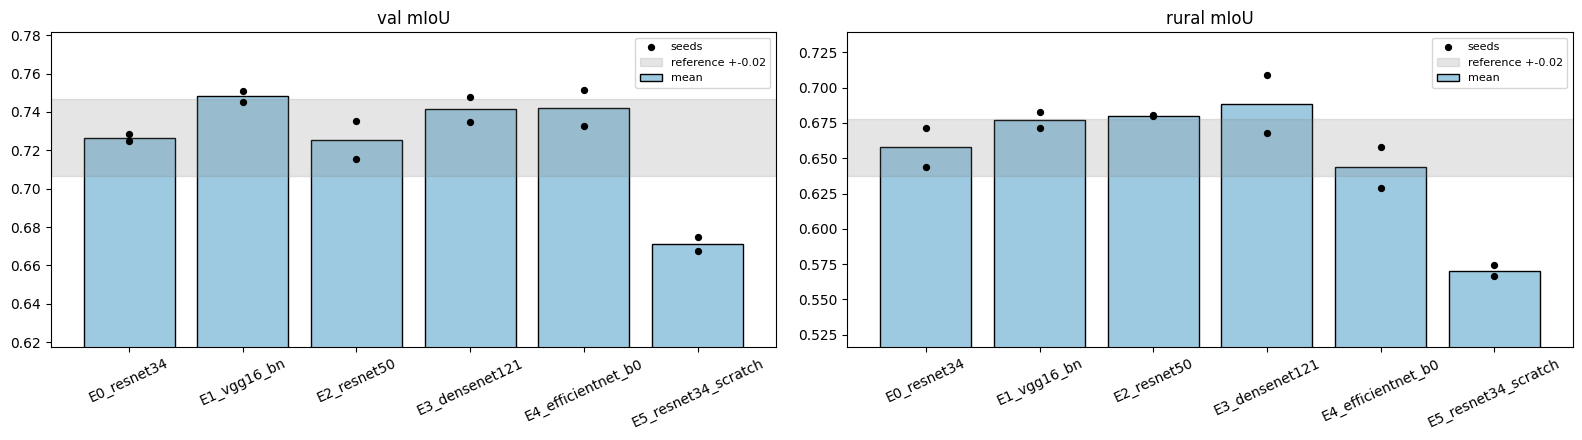

In [15]:
metrics = ["val mIoU", "rural mIoU", "rural mIoU smoothed", "rural mIoU all", "test mIoU all sites",
           "flicker %", "flicker smoothed %"]
g = runs.groupby("experiment", sort=False)
summary = g[metrics].mean()
summary["val spread"] = g["val mIoU"].agg(lambda v: v.max() - v.min())
summary["rural spread"] = g["rural mIoU"].agg(lambda v: v.max() - v.min())
summary[["parameters M", "s per epoch", "epochs", "train-val gap"]] = g[["parameters M", "s per epoch", "epochs",
                                                                        "train-val gap"]].mean()
ref = summary.loc[REFERENCE] if REFERENCE in summary.index else None
if ref is not None:
    summary["val vs reference"] = summary["val mIoU"] - ref["val mIoU"]
    summary["rural vs reference"] = summary["rural mIoU"] - ref["rural mIoU"]
    summary["beats reference"] = summary["val vs reference"] > NOISE
summary.to_csv(OUT / "summary.csv")
print(f"mean over {len(SEEDS)} seeds; spread = best seed - worst seed. Decision: mean val mIoU "
      f"(rural test only reported); a change counts only if it beats {REFERENCE} by more than {NOISE}.")
display(summary.round(3))

per_class = g[[f"IoU {c}" for c in CLASS_NAMES]].mean().T
per_class.index = CLASS_NAMES
print("rural test IoU per class (raw maps, agreement pixels, mean over seeds):")
display(per_class.round(3))
per_class.to_csv(OUT / "per_class_rural_IoU.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
names = list(summary.index)
for ax, metric in zip(axes, ["val mIoU", "rural mIoU"]):
    ax.bar(names, summary[metric], color="#9ecae1", edgecolor="black", label="mean")
    for k, name in enumerate(names):
        vals = runs[runs.experiment == name][metric]
        ax.scatter([k] * len(vals), vals, color="black", zorder=3, s=18, label="seeds" if k == 0 else None)
    if ref is not None:
        ax.axhspan(ref[metric] - NOISE, ref[metric] + NOISE, color="grey", alpha=0.2, label=f"reference +-{NOISE}")
    lo = runs[metric].min()
    ax.set_ylim(max(0, lo - 0.05), min(1, runs[metric].max() + 0.03))
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=25)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "comparison.png", dpi=120)
plt.show()

### 9.2 Validation curves

Validation mIoU per epoch for every run. Look for: a configuration that keeps improving when the others stop (it might need more epochs), or one that peaks early and falls (overfitting).

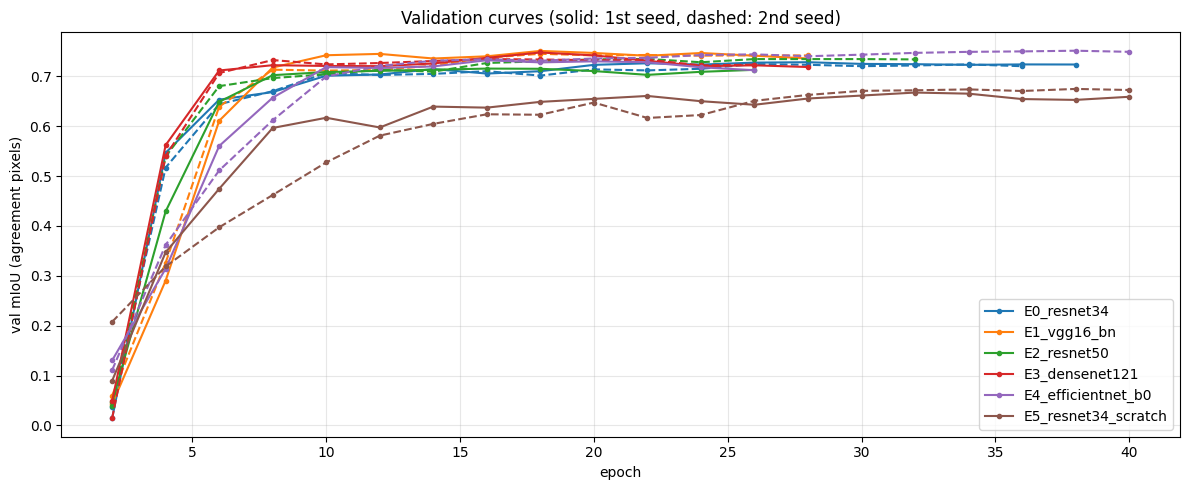

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.tab10.colors
for k, name in enumerate(CONFIGS):
    for j, seed in enumerate(SEEDS):
        h = histories.get(f"{name}_s{seed}")
        if h is not None:
            v = h.dropna(subset=["val_mIoU"])
            ax.plot(v.epoch, v.val_mIoU, color=colors[k % 10], ls="-" if j == 0 else "--",
                    marker="o", ms=3, label=name if j == 0 else None)
ax.set_xlabel("epoch")
ax.set_ylabel("val mIoU (agreement pixels)")
ax.set_title("Validation curves (solid: 1st seed, dashed: 2nd seed)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "val_curves.png", dpi=120)
plt.show()

### 9.3 The best configuration

The configuration with the best mean val mIoU and, of its seeds, the run with the best val mIoU. Its scores per region (compare with `Iter2_Test_1_Full`, printed above the table) and its confusion matrix on the rural test sites (row-normalised: recall on the diagonal).

best configuration by mean val mIoU: E1_vgg16_bn (run E1_vgg16_bn_s42)
it beats the reference by more than the noise: yes
winner per region (Iter2_Test_1_Full: africa 0.492, asia 0.656, europe 0.654, n_america 0.569, oceania 0.441, s_america 0.584):


,patches,OA,mIoU,mIoU smoothed,flicker %
region,,,,,
africa,64,0.824,0.520,0.521,2.999
asia,73,0.863,0.632,0.635,2.489
europe,32,0.966,0.700,0.702,0.969
n_america,48,0.837,0.612,0.614,2.917
oceania,16,0.978,0.473,0.472,0.533
s_america,32,0.905,0.625,0.625,1.440


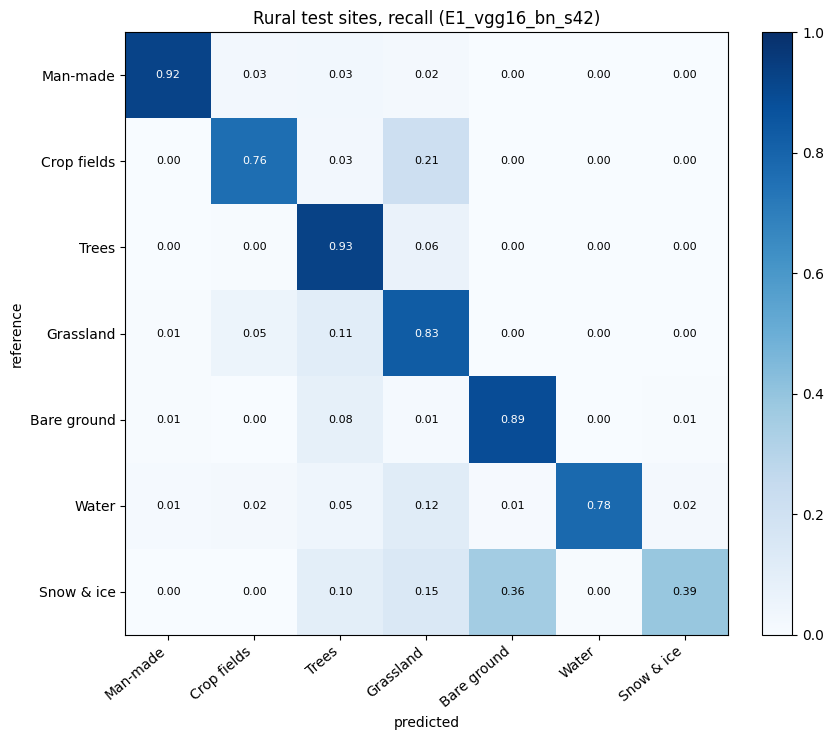

In [17]:
WINNER = summary["val mIoU"].idxmax()
win_runs = runs[runs.experiment == WINNER]
WINNER_RUN = win_runs.loc[win_runs["val mIoU"].idxmax(), "run"]
WINNER_CFG = CONFIGS[WINNER]
BEATS = bool(summary.loc[WINNER].get("beats reference", False)) if WINNER != REFERENCE else False
print(f"best configuration by mean val mIoU: {WINNER} (run {WINNER_RUN})")
print("it beats the reference by more than the noise:" if WINNER != REFERENCE else "the reference itself is best:",
      "yes" if BEATS else "no, keep Iter2_Test_1_Full as the final model")

model = UNet(input_channels(VARIANT), N_CLASSES, WINNER_CFG["encoder"], pretrained=False).to(
    DEVICE, memory_format=torch.channels_last)
model.load_state_dict(torch.load(RUNS_DIR / f"{WINNER_RUN}.pt", map_location=DEVICE))
model.eval()
results_rural = evaluate_year(model, "test", VARIANT, RURAL_IDS)
results_all = evaluate_year(model, "test", VARIANT)
USE_SMOOTHING = results_rural["smooth"]["mIoU"] >= results_rural["raw"]["mIoU"]


def group_scores(column):
    rows = []
    for group, df in index["test"].groupby(column):
        r = evaluate_year(model, "test", VARIANT, df.index.to_numpy())
        rows.append({column: group, "patches": len(df), "OA": r["raw"]["OA"], "mIoU": r["raw"]["mIoU"],
                     "mIoU smoothed": r["smooth"]["mIoU"], "flicker %": r["flicker"]["raw"] * 100})
    return pd.DataFrame(rows).set_index(column).round(3)


print("winner per region (Iter2_Test_1_Full: africa 0.492, asia 0.656, europe 0.654, n_america 0.569, "
      "oceania 0.441, s_america 0.584):")
display(group_scores("region"))

conf = results_rural["confusion"].astype(np.float64)
norm = conf / conf.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", color="white" if norm[i, j] > 0.5 else "black",
                fontsize=8)
ax.set_xticks(range(N_CLASSES), CLASS_NAMES, rotation=40, ha="right")
ax.set_yticks(range(N_CLASSES), CLASS_NAMES)
ax.set_xlabel("predicted")
ax.set_ylabel("reference")
ax.set_title(f"Rural test sites, recall ({WINNER_RUN})")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix_winner.png", dpi=120)
plt.show()

## 10. Export of the best run

`best_model.pt` + `model_card.json` in `Weights/<RUN_NAME>/`, in the same format as the 2nd iteration plus `encoder`, `experiment`, `run`, `training` and `beats_reference`. The prototype (`prototype/model.py`) builds the encoder named in the card, so it can load any run of this notebook.

**`final_model.pt` of `Iter2_Test_1_Full` stays the final model** unless `beats_reference` is true. Even then, run the prototype's rural tests with the new model before switching. The whole folder is zipped for one download.

In [18]:
model_card = {
    "iteration": 2,
    "experiment": WINNER,
    "run": WINNER_RUN,
    "beats_reference": BEATS,
    "variant": VARIANT_NAME,
    "n_months": VARIANT["n_months"],
    "in_channels": input_channels(VARIANT),
    "encoder": WINNER_CFG["encoder"],
    "training": WINNER_CFG,
    "channels_per_month": ["VV_dB", "VH_dB", "VV_minus_VH_dB"],
    "month_window": "target month and the previous n_months-1 months, oldest first (wrapping around the year)",
    "static_channels": STAT_NAMES,
    "channel_order": "monthly channels (oldest month first), then static_channels",
    "s1_preprocessing": S1_PREPROCESSING,
    "stats_definition": "over the 12 months in dB: VV mean, VH mean, (VV-VH) mean, VV 2nd lowest, VV 2nd highest, "
                        "VH 2nd lowest, VH 2nd highest, VH std, share of valid months with VV < "
                        f"{WATER_DB} dB (missing months filled with the pixel mean before sorting); "
                        "standardised with stats_mean/std",
    "stats_mean": STAT_MEAN.tolist(),
    "stats_std": STAT_STD.tolist(),
    "channel_mean": CH_MEAN.tolist(),
    "channel_std": CH_STD.tolist(),
    "temporal_smoothing": ("mean softmax of months t-1, t, t+1 (wrapping) before argmax" if USE_SMOOTHING else "none"),
    "label": "ESA WorldCover 2021 on all pixels; Dynamic World agreement pixels weight 1, others "
             f"{WINNER_CFG['disagree_weight']}; scores on agreement pixels",
    "ema_decay": EMA_DECAY,
    "nan_fill_after_standardisation": 0.0,
    "db_decoding": {"db_min": DB_MIN, "db_step": DB_STEP, "nodata_code": 0},
    "class_names": CLASS_NAMES,
    "class_colors": CLASS_COLORS,
    "patch_size": PATCH,
    "architecture": f"UNet with a {WINNER_CFG['encoder']} encoder ({NOTEBOOK})",
    "weights": "best_model.pt",
    "test_rural_mIoU": results_rural["raw"]["mIoU"],
    "test_rural_mIoU_smoothed": results_rural["smooth"]["mIoU"],
    "test_rural_flicker": results_rural["flicker"],
    "test_mIoU": results_all["raw"]["mIoU"],
}
shutil.copy(RUNS_DIR / f"{WINNER_RUN}.pt", OUT / "best_model.pt")
json.dump(model_card, open(OUT / "model_card.json", "w"), indent=2)
archive = shutil.make_archive(str(OUT), "zip", OUT)
print({k: v for k, v in model_card.items() if k not in ("stats_mean", "stats_std")})
print("saved:", sorted(p.name for p in OUT.iterdir()))
print("archive:", archive)

{'iteration': 2, 'experiment': 'E1_vgg16_bn', 'run': 'E1_vgg16_bn_s42', 'beats_reference': True, 'variant': 'month_year', 'n_months': 1, 'in_channels': 12, 'encoder': 'vgg16_bn', 'training': {'encoder': 'vgg16_bn', 'pretrained': True, 'optimizer': 'adamw', 'lr': 0.0006, 'weight_decay': 0.05, 'lovasz_weight': 0.5, 'disagree_weight': 0.5, 'label_smoothing': 0.1, 'bootstrap_beta': 1.0}, 'channels_per_month': ['VV_dB', 'VH_dB', 'VV_minus_VH_dB'], 'month_window': 'target month and the previous n_months-1 months, oldest first (wrapping around the year)', 'static_channels': ['VV mean', 'VH mean', 'VV-VH mean', 'VV low', 'VV high', 'VH low', 'VH high', 'VH std', 'water months'], 'channel_order': 'monthly channels (oldest month first), then static_channels', 's1_preprocessing': 'S1_GRD IW VV+VH asc+desc; gamma0 terrain flattening (Vollrath 2020 volume model, GLO-30); layover/shadow/incidence 31-45 deg masked; monthly linear mean; dB; no spatial filter', 'stats_definition': 'over the 12 months i